In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sakhawat18/asteroid-dataset/dataset.csv
/kaggle/input/datasets/aradhanawalmiki/asteriod-dataset-nasa/asteroid_dataset.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

In [3]:
df=pd.read_csv("/kaggle/input/datasets/sakhawat18/asteroid-dataset/dataset.csv")

/tmp/ipykernel_16/2599889401.py:1: DtypeWarning: Columns (3,4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("/kaggle/input/datasets/sakhawat18/asteroid-dataset/dataset.csv")


In [4]:
df.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


In [5]:
print("Shape:", df.shape)

print("\nInformation:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

Shape: (958524, 45)

Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 958524 entries, 0 to 958523
Data columns (total 45 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              958524 non-null  object 
 1   spkid           958524 non-null  int64  
 2   full_name       958524 non-null  object 
 3   pdes            958524 non-null  object 
 4   name            22064 non-null   object 
 5   prefix          18 non-null      object 
 6   neo             958520 non-null  object 
 7   pha             938603 non-null  object 
 8   H               952261 non-null  float64
 9   diameter        136209 non-null  float64
 10  albedo          135103 non-null  float64
 11  diameter_sigma  136081 non-null  float64
 12  orbit_id        958524 non-null  object 
 13  epoch           958524 non-null  float64
 14  epoch_mjd       958524 non-null  int64  
 15  epoch_cal       958524 non-null  float64
 16  equinox         958524

,spkid,H,diameter,albedo,diameter_sigma,epoch,epoch_mjd,epoch_cal,e,a,...,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,rms
count,9.585240e+05,952261.000000,136209.000000,135103.000000,136081.000000,9.585240e+05,958524.000000,9.585240e+05,958524.000000,958524.000000,...,9.386020e+05,9.386020e+05,9.386020e+05,9.386020e+05,9.386020e+05,9.385980e+05,9.386020e+05,9.386020e+05,9.385980e+05,958522.000000
mean,3.810114e+06,16.906411,5.506429,0.130627,0.479184,2.458869e+06,58868.781950,2.019693e+07,0.156116,2.902143,...,1.982929e+01,1.168449e+00,5.310234e+00,1.370062e+06,1.369977e+06,2.131453e+01,5.060221e-02,4.312780e+08,8.525815e+04,0.561153
std,6.831541e+06,1.790405,9.425164,0.110323,0.782895,7.016716e+02,701.671573,1.930354e+04,0.092643,39.719503,...,2.903785e+03,1.282231e+02,1.333381e+03,9.158996e+08,9.158991e+08,7.197034e+03,9.814953e+00,2.953046e+11,2.767681e+07,2.745700
min,2.000001e+06,-1.100000,0.002500,0.001000,0.000500,2.425052e+06,25051.000000,1.927062e+07,0.000000,-14702.447872,...,1.956900e-11,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,0.000000
25%,2.239632e+06,16.100000,2.780000,0.053000,0.180000,2.459000e+06,59000.000000,2.020053e+07,0.092193,2.387835,...,1.462000e-07,6.095900e-06,3.619400e-05,5.755000e-05,2.573700e-05,2.340900e-08,2.768800e-09,1.110900e-04,1.794500e-05,0.518040
50%,2.479262e+06,16.900000,3.972000,0.079000,0.332000,2.459000e+06,59000.000000,2.020053e+07,0.145002,2.646969,...,2.271900e-07,8.688800e-06,6.642550e-05,1.047100e-04,4.900100e-05,4.359000e-08,4.638000e-09,2.230800e-04,3.501700e-05,0.566280
75%,3.752518e+06,17.714000,5.765000,0.190000,0.620000,2.459000e+06,59000.000000,2.020053e+07,0.200650,3.001932,...,6.583200e-07,1.591500e-05,1.609775e-04,3.114400e-04,1.718900e-04,1.196600e-07,1.124000e-08,8.139600e-04,9.775475e-05,0.613927
max,5.401723e+07,33.200000,939.400000,1.000000,140.000000,2.459000e+06,59000.000000,2.020053e+07,1.855356,33488.895955,...,1.015000e+06,5.533000e+04,1.199100e+06,8.845100e+11,8.845100e+11,5.509700e+06,7.698800e+03,2.853100e+14,1.910700e+10,2686.600000



Missing values:
id                     0
spkid                  0
full_name              0
pdes                   0
name              936460
prefix            958506
neo                    4
pha                19921
H                   6263
diameter          822315
albedo            823421
diameter_sigma    822443
orbit_id               0
epoch                  0
epoch_mjd              0
epoch_cal              0
equinox                0
e                      0
a                      0
q                      0
i                      0
om                     0
w                      0
ma                     1
ad                     4
n                      0
tp                     0
tp_cal                 0
per                    4
per_y                  1
moid               19921
moid_ld              127
sigma_e            19922
sigma_a            19922
sigma_q            19922
sigma_i            19922
sigma_om           19922
sigma_w            19922
sigma_ma           19922
sigma_ad

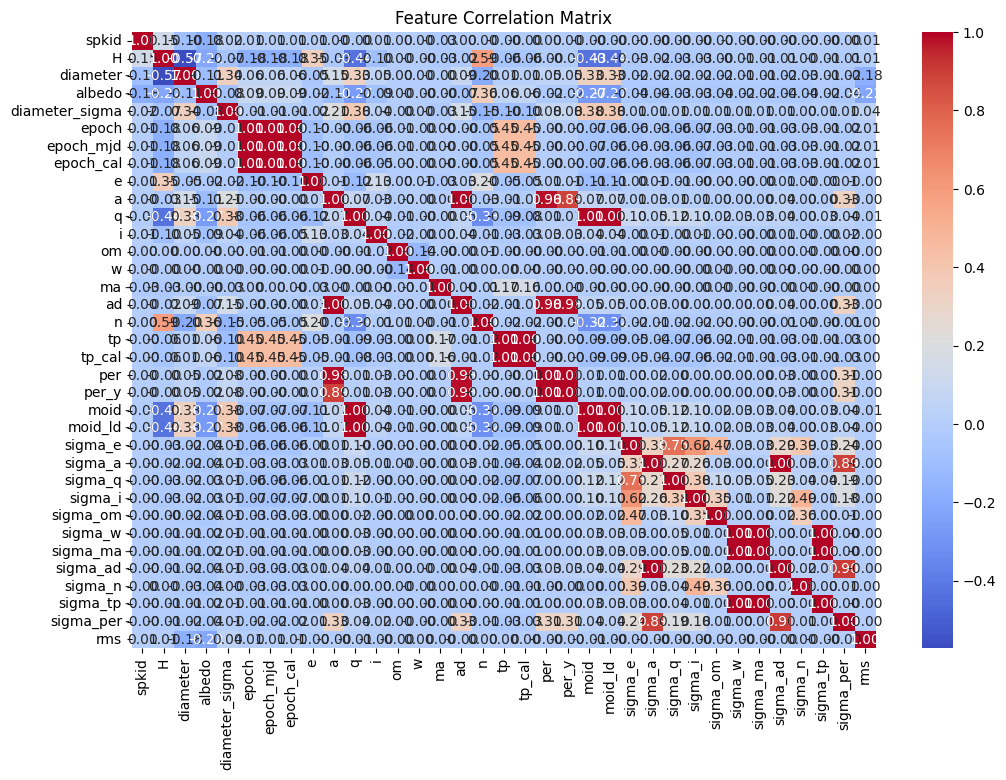

In [6]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Matrix")
plt.show()

In [7]:
print("NEO distribution:")
print(df['neo'].value_counts(dropna=False))

print("\nPHA distribution:")
print(df['pha'].value_counts(dropna=False))

NEO distribution:
neo
N      935625
Y       22895
NaN         4
Name: count, dtype: int64

PHA distribution:
pha
N      936537
NaN     19921
Y        2066
Name: count, dtype: int64


In [8]:
neo_df = df[
    (df['neo'] == 'Y') &
    (df['pha'].isin(['Y', 'N']))
].copy()

print("NEO dataset shape:", neo_df.shape)

print("\nTarget distribution:")
print(neo_df['pha'].value_counts())

print("\nTarget percentage:")
print(neo_df['pha'].value_counts(normalize=True) * 100)

NEO dataset shape: (22894, 45)

Target distribution:
pha
N    20828
Y     2066
Name: count, dtype: int64

Target percentage:
pha
N    90.975802
Y     9.024198
Name: proportion, dtype: float64


In [9]:
# Missing value analysis on filtered NEO dataset

missing_analysis = pd.DataFrame({
    'Missing_Count': neo_df.isnull().sum(),
    'Missing_Percentage': neo_df.isnull().mean() * 100,
    'Data_Type': neo_df.dtypes
})

missing_analysis = missing_analysis.sort_values(
    by='Missing_Percentage',
    ascending=False
)

display(missing_analysis)

,Missing_Count,Missing_Percentage,Data_Type
prefix,22893,99.995632,object
name,22732,99.292391,object
diameter_sigma,22134,96.680353,float64
albedo,22092,96.496899,float64
diameter,22045,96.291605,float64
H,11,0.048048,float64
full_name,0,0.000000,object
spkid,0,0.000000,int64
id,0,0.000000,object
pdes,0,0.000000,object


In [10]:
# Check number of unique values in each column

unique_analysis = pd.DataFrame({
    'Unique_Values': neo_df.nunique(),
    'Data_Type': neo_df.dtypes
})

unique_analysis = unique_analysis.sort_values(
    by='Unique_Values',
    ascending=True
)

display(unique_analysis)

,Unique_Values,Data_Type
neo,1,object
prefix,1,object
equinox,1,object
pha,2,object
class,4,object
name,162,object
diameter_sigma,284,float64
albedo,359,float64
orbit_id,521,object
diameter,671,float64


In [11]:
# Identify columns with only one unique value

constant_columns = unique_analysis[
    unique_analysis['Unique_Values'] == 1
].index.tolist()

print("Constant columns:", constant_columns)

Constant columns: ['neo', 'prefix', 'equinox']


In [12]:
# Drop constant columns

neo_df = neo_df.drop(columns=constant_columns)

print("Updated dataset shape:", neo_df.shape)

Updated dataset shape: (22894, 42)


In [13]:
# Select numerical columns
numerical_df = neo_df.select_dtypes(include=['number'])

# Calculate correlation matrix
correlation_matrix = numerical_df.corr()

display(correlation_matrix.round(2))

,spkid,H,diameter,albedo,diameter_sigma,epoch,epoch_mjd,epoch_cal,e,a,...,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,rms
spkid,1.00,0.13,-0.30,-0.24,-0.12,0.08,0.08,0.08,-0.02,-0.01,...,-0.01,-0.00,-0.00,-0.01,-0.01,-0.00,-0.00,-0.01,-0.00,0.04
H,0.13,1.00,-0.58,-0.17,-0.32,-0.21,-0.21,-0.21,-0.27,-0.07,...,-0.01,-0.01,0.00,0.01,-0.00,-0.01,-0.00,-0.00,-0.00,0.01
diameter,-0.30,-0.58,1.00,-0.10,0.33,0.11,0.11,0.11,0.12,0.23,...,-0.00,-0.02,-0.02,-0.00,-0.01,-0.02,-0.02,-0.02,-0.02,-0.12
albedo,-0.24,-0.17,-0.10,1.00,-0.20,0.00,0.00,0.01,-0.13,-0.23,...,-0.03,-0.05,-0.05,-0.03,-0.04,-0.05,-0.04,-0.04,-0.05,0.00
diameter_sigma,-0.12,-0.32,0.33,-0.20,1.00,0.09,0.09,0.09,0.13,0.26,...,0.01,-0.01,-0.01,0.00,-0.00,-0.01,-0.01,-0.01,-0.02,0.01
epoch,0.08,-0.21,0.11,0.00,0.09,1.00,1.00,1.00,-0.08,-0.00,...,-0.06,-0.05,-0.05,-0.07,-0.05,-0.04,-0.06,-0.03,-0.00,0.00
epoch_mjd,0.08,-0.21,0.11,0.00,0.09,1.00,1.00,1.00,-0.08,-0.00,...,-0.06,-0.05,-0.05,-0.07,-0.05,-0.04,-0.06,-0.03,-0.00,0.00
epoch_cal,0.08,-0.21,0.11,0.01,0.09,1.00,1.00,1.00,-0.08,-0.00,...,-0.06,-0.05,-0.05,-0.07,-0.05,-0.04,-0.06,-0.03,-0.00,0.00
e,-0.02,-0.27,0.12,-0.13,0.13,-0.08,-0.08,-0.08,1.00,0.18,...,-0.00,0.01,0.00,-0.02,-0.00,0.04,0.02,-0.00,0.03,-0.01
a,-0.01,-0.07,0.23,-0.23,0.26,-0.00,-0.00,-0.00,0.18,1.00,...,0.00,0.00,0.00,0.00,-0.00,0.67,0.00,0.00,0.96,-0.00


In [14]:
# Extract highly correlated feature pairs

correlation_threshold = 0.90

upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_correlations = (
    upper_triangle
    .stack()
    .reset_index()
)

high_correlations.columns = [
    'Feature_1',
    'Feature_2',
    'Correlation'
]

high_correlations = high_correlations[
    high_correlations['Correlation'].abs() > correlation_threshold
].sort_values(
    by='Correlation',
    key=abs,
    ascending=False
)

display(high_correlations)

,Feature_1,Feature_2,Correlation
475,per,per_y,1.000000
504,moid,moid_ld,1.000000
160,epoch,epoch_mjd,1.000000
161,epoch,epoch_cal,0.999323
189,epoch_mjd,epoch_cal,0.999323
275,a,ad,0.998852
442,tp,tp_cal,0.997869
545,sigma_a,sigma_ad,0.992017
502,per_y,sigma_per,0.991767
488,per,sigma_per,0.991767


In [15]:
# Identify features that may cause target leakage

leakage_columns = ['H', 'moid', 'moid_ld']

print("Potential target leakage columns:")
print(leakage_columns)

Potential target leakage columns:
['H', 'moid', 'moid_ld']


In [16]:
# Columns to exclude from initial modelling

columns_to_exclude = [
    'spkid',           # Identifier
    'H',               # Target leakage
    'moid',            # Target leakage
    'moid_ld',         # Duplicate of MOID
    'diameter',        # Too many missing values
    'albedo',          # Too many missing values
    'diameter_sigma',  # Too many missing values
    'epoch',           # Time representation
    'epoch_mjd',       # Duplicate time representation
    'epoch_cal',       # Duplicate time representation
    'tp_cal',          # Alternate time representation
    'ad',              # Redundant orbital parameter
    'per_y'            # Orbital period in alternate units
]

model_df = neo_df.drop(columns=columns_to_exclude)

print("Model dataset shape:", model_df.shape)
print("\nRemaining columns:")
print(model_df.columns.tolist())

Model dataset shape: (22894, 29)

Remaining columns:
['id', 'full_name', 'pdes', 'name', 'pha', 'orbit_id', 'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'n', 'tp', 'per', 'sigma_e', 'sigma_a', 'sigma_q', 'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma', 'sigma_ad', 'sigma_n', 'sigma_tp', 'sigma_per', 'class', 'rms']


In [17]:
# Separate features and target

X = model_df.drop(columns=['pha'])
y = model_df['pha']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (22894, 28)
Target shape: (22894,)

Target distribution:
pha
N    20828
Y     2066
Name: count, dtype: int64


In [18]:
# Check feature data types

print("Numerical features:")
print(X.select_dtypes(include=['number']).columns.tolist())

print("\nCategorical features:")
print(X.select_dtypes(include=['object', 'category']).columns.tolist())

Numerical features:
['e', 'a', 'q', 'i', 'om', 'w', 'ma', 'n', 'tp', 'per', 'sigma_e', 'sigma_a', 'sigma_q', 'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma', 'sigma_ad', 'sigma_n', 'sigma_tp', 'sigma_per', 'rms']

Categorical features:
['id', 'full_name', 'pdes', 'name', 'orbit_id', 'class']


In [19]:
# Remove identifier columns

identifier_columns = ['id', 'full_name', 'pdes', 'name', 'orbit_id']

X = X.drop(columns=identifier_columns)

print("Updated feature shape:", X.shape)
print("\nRemaining features:")
print(X.columns.tolist())

Updated feature shape: (22894, 23)

Remaining features:
['e', 'a', 'q', 'i', 'om', 'w', 'ma', 'n', 'tp', 'per', 'sigma_e', 'sigma_a', 'sigma_q', 'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma', 'sigma_ad', 'sigma_n', 'sigma_tp', 'sigma_per', 'class', 'rms']


In [20]:
# Check missing values in remaining features

missing_features = X.isnull().sum()

missing_features = missing_features[missing_features > 0].sort_values(
    ascending=False
)

display(missing_features)

Series([], dtype: int64)

In [21]:
# Encode target labels

y = y.map({'N': 0, 'Y': 1})

print(y.value_counts())
print("\nTarget data type:", y.dtype)

pha
0    20828
1     2066
Name: count, dtype: int64

Target data type: int64


In [22]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 18315
Testing samples: 4579

Training target distribution:
pha
0    16662
1     1653
Name: count, dtype: int64

Testing target distribution:
pha
0    4166
1     413
Name: count, dtype: int64


In [23]:
# Separate numerical and categorical features

numerical_features = X.select_dtypes(include=['number']).columns.tolist()

categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", categorical_features)

Numerical features: 22
Categorical features: ['class']


Numerical features → StandardScaler

Categorical features (class) → OneHotEncoder

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Create preprocessing transformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Fit on training data and transform
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the already fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (18315, 26)
Processed testing shape: (4579, 26)


In [25]:
# Inspect encoded categorical categories

print("Orbital classes:", preprocessor.named_transformers_['cat'].categories_)
print("Number of encoded class columns:", 
      len(preprocessor.named_transformers_['cat'].categories_[0]))

Orbital classes: [array(['AMO', 'APO', 'ATE', 'IEO'], dtype=object)]
Number of encoded class columns: 4


In [26]:
from sklearn.svm import SVC

# Initialize SVM classifier
svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale'
)

# Train the model
svm_model.fit(X_train_processed, y_train)

print("SVM model training completed!")

SVM model training completed!


kernel='rbf' → Learns nonlinear decision boundaries.



C=1.0 → Controls the trade-off between margin size and training errors.



gamma='scale' → Automatically determines how far the influence of each training sample extends.

Gamma in SVM: Gamma is a parameter used with the RBF kernel. It controls the influence of individual training data points on the decision boundary. High gamma creates a more complex boundary, while low gamma creates a smoother boundary. gamma='scale' automatically calculates the value based on the dataset.

In [27]:
# Predict on test data

y_pred = svm_model.predict(X_test_processed)

print("Predictions completed!")
print("Total predictions:", len(y_pred))

Predictions completed!
Total predictions: 4579


In [28]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=['Non-Hazardous', 'Hazardous']
))

               precision    recall  f1-score   support

Non-Hazardous       0.91      1.00      0.95      4166
    Hazardous       0.00      0.00      0.00       413

     accuracy                           0.91      4579
    macro avg       0.45      0.50      0.48      4579
 weighted avg       0.83      0.91      0.87      4579



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [29]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[4166    0]
 [ 413    0]]


In [30]:
# Train SVM with balanced class weights

svm_balanced = SVC(
    kernel='rbf',
    C=1.5,
    gamma='scale',
    class_weight='balanced'
)

svm_balanced.fit(X_train_processed, y_train)

print("Balanced SVM training completed!")

Balanced SVM training completed!


In [31]:
# Predict using balanced SVM

y_pred_balanced = svm_balanced.predict(X_test_processed)

print("Balanced SVM predictions completed!")

Balanced SVM predictions completed!


In [32]:
# Evaluate balanced SVM

print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=['Non-Hazardous', 'Hazardous']
))

               precision    recall  f1-score   support

Non-Hazardous       0.97      0.69      0.81      4166
    Hazardous       0.21      0.82      0.33       413

     accuracy                           0.70      4579
    macro avg       0.59      0.75      0.57      4579
 weighted avg       0.91      0.70      0.76      4579



In [33]:
cm_balanced = confusion_matrix(y_test, y_pred_balanced)

print(cm_balanced)

[[2863 1303]
 [  74  339]]


In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Original SVM': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ],
    'Balanced SVM': [
        accuracy_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_balanced)
    ]
})

display(comparison.round(3))

,Metric,Original SVM,Balanced SVM
0,Accuracy,0.91,0.699
1,Precision,0.00,0.206
2,Recall,0.00,0.821
3,F1-score,0.00,0.330


## SVM Kernel Comparison

In this section, we will experiment with four different SVM kernels to understand how kernel selection affects asteroid hazardous prediction.

The kernels used are:
1. Linear Kernel
2. Polynomial Kernel
3. RBF (Radial Basis Function) Kernel
4. Sigmoid Kernel

All models will use the same training and testing datasets, preprocessing pipeline, and class-weight balancing to ensure a fair comparison.

In [35]:
from sklearn.svm import SVC

svm_models = {
    'Linear': SVC(
        kernel='linear',
        C=1.5,
        class_weight='balanced',
        cache_size=1000
    ),

    'Polynomial': SVC(
        kernel='poly',
        degree=3,
        C=1.5,
        gamma='scale',
        class_weight='balanced',
        cache_size=1000
    ),

    'RBF': SVC(
        kernel='rbf',
        C=1.5,
        gamma='scale',
        class_weight='balanced',
        cache_size=1000
    ),

    'Sigmoid': SVC(
        kernel='sigmoid',
        C=1.5,
        gamma='scale',
        class_weight='balanced',
        cache_size=1000
    )
}

print("Four SVM kernel models initialized successfully!")

Four SVM kernel models initialized successfully!


In [36]:
# Dictionary to store predictions

kernel_predictions = {}

# Train each kernel model

for kernel_name, model in svm_models.items():

    print(f"\nTraining {kernel_name} SVM...")

    model.fit(X_train_processed, y_train)

    # Predict on test data
    y_pred_kernel = model.predict(X_test_processed)

    # Store predictions
    kernel_predictions[kernel_name] = y_pred_kernel

    print(f"{kernel_name} SVM training completed!")


Training Linear SVM...
Linear SVM training completed!

Training Polynomial SVM...
Polynomial SVM training completed!

Training RBF SVM...
RBF SVM training completed!

Training Sigmoid SVM...
Sigmoid SVM training completed!


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

kernel_results = []

for kernel_name, model in svm_models.items():

    y_pred_kernel = kernel_predictions[kernel_name]

    # Decision scores for ranking-based metrics
    y_scores = model.decision_function(X_test_processed)

    kernel_results.append({
        'Kernel': kernel_name,

        'Accuracy': accuracy_score(
            y_test, y_pred_kernel
        ),

        'Precision': precision_score(
            y_test, y_pred_kernel, zero_division=0
        ),

        'Recall': recall_score(
            y_test, y_pred_kernel, zero_division=0
        ),

        'F1-score': f1_score(
            y_test, y_pred_kernel, zero_division=0
        ),

        'ROC-AUC': roc_auc_score(
            y_test, y_scores
        ),

        'PR-AUC': average_precision_score(
            y_test, y_scores
        )
    })

kernel_comparison = pd.DataFrame(kernel_results)

display(
    kernel_comparison.round(3)
)

,Kernel,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Linear,0.537,0.150,0.886,0.257,0.782,0.221
1,Polynomial,0.670,0.191,0.821,0.310,0.800,0.237
2,RBF,0.699,0.206,0.821,0.330,0.830,0.296
3,Sigmoid,0.559,0.117,0.596,0.196,0.604,0.117
